In [1]:
import joblib
import os
import glob

# Wczytanie wszystkich zapisanych modeli
models_dir = 'models'
model_files = glob.glob(os.path.join(models_dir, '*_compression_model.pkl'))

loaded_results = {}

print("Wczytywanie zapisanych modeli...")
print("=" * 70)

for model_path in model_files:
    # Wyciągnij nazwę modelu z nazwy pliku
    model_filename = os.path.basename(model_path)
    # Usuń '_compression_model.pkl' i zamień podkreślniki na spacje
    model_name = model_filename.replace('_compression_model.pkl', '').replace('_', ' ').title()
    
    # Pomiń best_model
    if model_name == 'Best':
        continue
    
    # Wczytaj model
    model = joblib.load(model_path)
    loaded_results[model_name] = {'model': model}
    
    print(f"✓ Wczytano: {model_name}")
    print(f"  Plik: {model_filename}")
    print(f"  Typ: {type(model).__name__}")
    print()

print(f"\nŁącznie wczytano {len(loaded_results)} modeli")
print("=" * 70)


Wczytywanie zapisanych modeli...
✓ Wczytano: Gradient Boosting
  Plik: gradient_boosting_compression_model.pkl
  Typ: GradientBoostingRegressor

✓ Wczytano: Linear Regression
  Plik: linear_regression_compression_model.pkl
  Typ: LinearRegression

✓ Wczytano: Gradient Boosting
  Plik: gradient_boosting_compression_model.pkl
  Typ: GradientBoostingRegressor

✓ Wczytano: Linear Regression
  Plik: linear_regression_compression_model.pkl
  Typ: LinearRegression

✓ Wczytano: Random Forest
  Plik: random_forest_compression_model.pkl
  Typ: RandomForestRegressor

✓ Wczytano: Svr
  Plik: svr_compression_model.pkl
  Typ: SVR


Łącznie wczytano 4 modeli
✓ Wczytano: Random Forest
  Plik: random_forest_compression_model.pkl
  Typ: RandomForestRegressor

✓ Wczytano: Svr
  Plik: svr_compression_model.pkl
  Typ: SVR


Łącznie wczytano 4 modeli


Dane JFIF wczytane: 11000 próbek
✓ Predykcja wykonana: Gradient Boosting
✓ Predykcja wykonana: Linear Regression
✓ Predykcja wykonana: Random Forest
✓ Predykcja wykonana: Svr



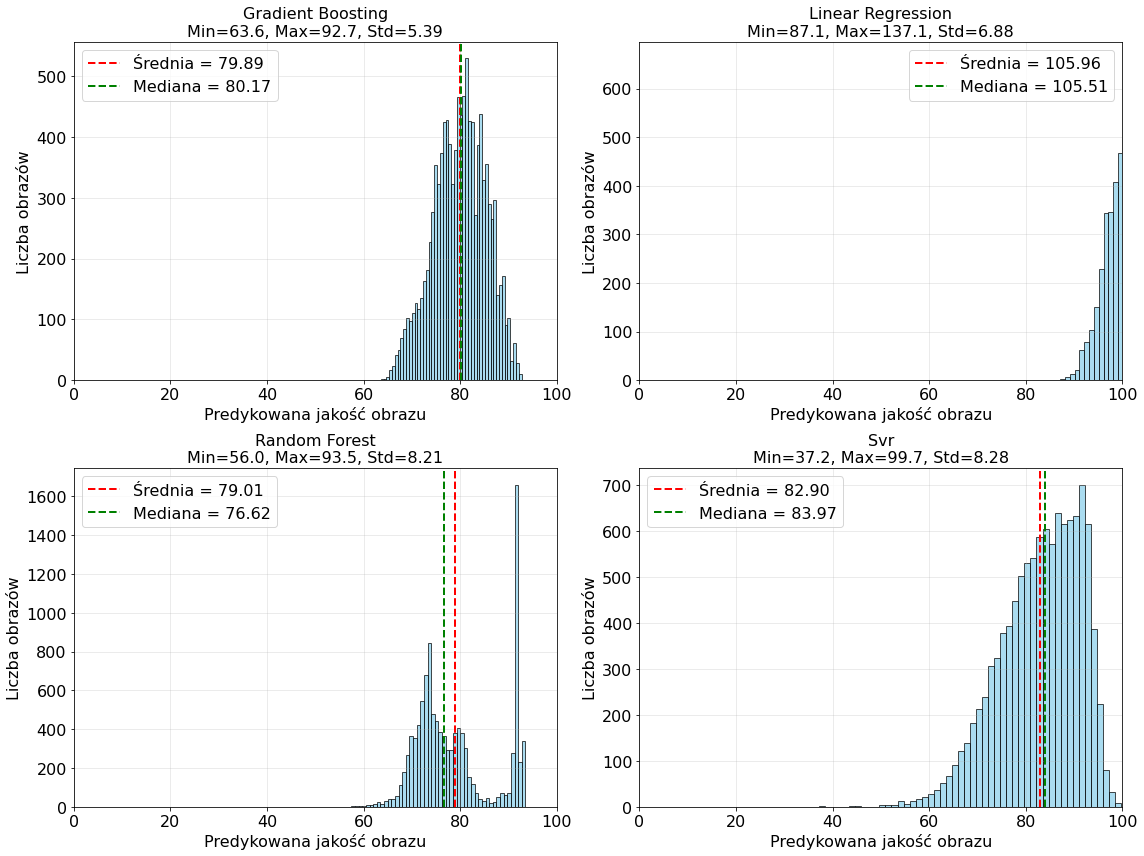


Statystyki predykcji jakości dla obrazów JFIF (wczytane modele):

Gradient Boosting:
  Średnia: 79.89
  Mediana: 80.17
  Odch. std.: 5.39
  Min: 63.56
  Max: 92.70
  Q1 (25%): 76.15
  Q3 (75%): 83.97

Linear Regression:
  Średnia: 105.96
  Mediana: 105.51
  Odch. std.: 6.88
  Min: 87.11
  Max: 137.10
  Q1 (25%): 101.04
  Q3 (75%): 110.26

Random Forest:
  Średnia: 79.01
  Mediana: 76.62
  Odch. std.: 8.21
  Min: 55.99
  Max: 93.49
  Q1 (25%): 72.80
  Q3 (75%): 87.59

Svr:
  Średnia: 82.90
  Mediana: 83.97
  Odch. std.: 8.28
  Min: 37.19
  Max: 99.73
  Q1 (25%): 77.47
  Q3 (75%): 89.58



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Parametr wielkości czcionki dla wszystkich wykresów
FONT_SIZE = 16

# Wczytanie danych JFIF
from_csv = pd.read_csv('results_jfif.csv')
from_csv = from_csv.dropna()
X_from_csv = from_csv.drop(['filename', 'extension', 'estimated_quality'], axis=1)

print(f"Dane JFIF wczytane: {len(X_from_csv)} próbek")
print("=" * 70)

# Predykcja jakości dla obrazów JFIF
y_pred_jfif_loaded = {}
for name, res in loaded_results.items():
    y_pred_jfif_loaded[name] = res['model'].predict(X_from_csv)
    print(f"✓ Predykcja wykonana: {name}")

print("\n" + "=" * 70)

# Wizualizacja predykcji dla wszystkich modeli
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

for idx, (name, y_pred) in enumerate(y_pred_jfif_loaded.items()):
    # Histogram predykowanych wartości
    axes[idx].hist(y_pred, bins=50, alpha=0.7, edgecolor='black', color='skyblue')
    axes[idx].axvline(x=y_pred.mean(), color='r', linestyle='--', lw=2, 
                      label=f'Średnia = {y_pred.mean():.2f}')
    axes[idx].axvline(x=np.median(y_pred), color='g', linestyle='--', lw=2, 
                      label=f'Mediana = {np.median(y_pred):.2f}')
    axes[idx].set_xlabel('Predykowana jakość obrazu', fontsize=FONT_SIZE)
    axes[idx].set_ylabel('Liczba obrazów', fontsize=FONT_SIZE)
    axes[idx].set_title(f'{name}\nMin={y_pred.min():.1f}, Max={y_pred.max():.1f}, Std={y_pred.std():.2f}', 
                        fontsize=FONT_SIZE)
    # axes[idx].set_yscale('log')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend(fontsize=FONT_SIZE)
    axes[idx].set_xlim(0, 100)
    axes[idx].tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
plt.savefig('jfif_quality_predictions_loaded_models.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nStatystyki predykcji jakości dla obrazów JFIF (wczytane modele):")
print("="*70)
for name, y_pred in y_pred_jfif_loaded.items():
    print(f"\n{name}:")
    print(f"  Średnia: {y_pred.mean():.2f}")
    print(f"  Mediana: {np.median(y_pred):.2f}")
    print(f"  Odch. std.: {y_pred.std():.2f}")
    print(f"  Min: {y_pred.min():.2f}")
    print(f"  Max: {y_pred.max():.2f}")
    print(f"  Q1 (25%): {np.percentile(y_pred, 25):.2f}")
    print(f"  Q3 (75%): {np.percentile(y_pred, 75):.2f}")

print("\n" + "="*70)


# Predykcja na jednym modelu

Dane JFIF wczytane: 11338 próbek
✓ Predykcja wykonana: Random Forest



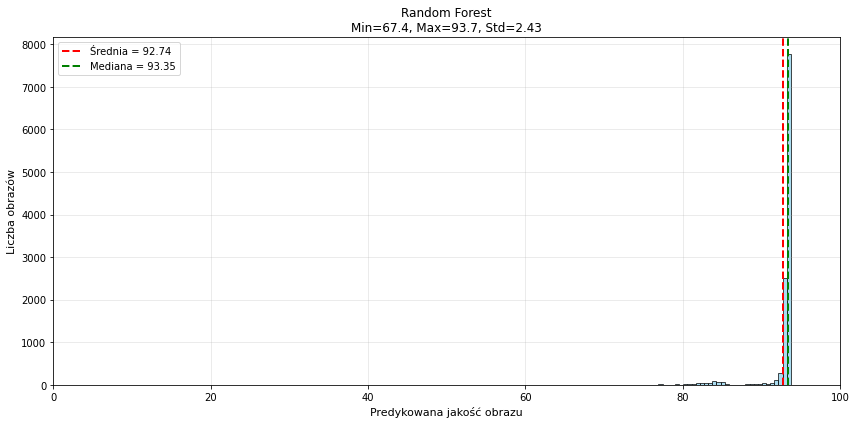


Statystyki predykcji jakości dla obrazów JFIF (Random Forest):
  Średnia: 92.74
  Mediana: 93.35
  Odch. std.: 2.43
  Min: 67.44
  Max: 93.74
  Q1 (25%): 93.14
  Q3 (75%): 93.47



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FILENAME = "results_iFakeFaceDB.csv"
FILENAME = "results_ppm.csv"

# Wczytanie danych JFIF
from_csv = pd.read_csv(FILENAME)
from_csv = from_csv.dropna()
X_from_csv = from_csv.drop(['filename', 'extension', 'estimated_quality'], axis=1)

print(f"Dane JFIF wczytane: {len(X_from_csv)} próbek")
print("=" * 70)

# Wybierz jeden model (np. Gradient Boosting)
model_name = 'Random Forest'
model = loaded_results[model_name]['model']

# Predykcja jakości dla obrazów JFIF
y_pred = model.predict(X_from_csv)
print(f"✓ Predykcja wykonana: {model_name}")

print("\n" + "=" * 70)

# Wizualizacja predykcji
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(y_pred, bins=50, alpha=0.7, edgecolor='black', color='skyblue')
ax.axvline(x=y_pred.mean(), color='r', linestyle='--', lw=2, 
          label=f'Średnia = {y_pred.mean():.2f}')
ax.axvline(x=np.median(y_pred), color='g', linestyle='--', lw=2, 
          label=f'Mediana = {np.median(y_pred):.2f}')
ax.set_xlabel('Predykowana jakość obrazu', fontsize=FONT_SIZE)
ax.set_ylabel('Liczba obrazów', fontsize=FONT_SIZE)
ax.set_title(f'{model_name}\nMin={y_pred.min():.1f}, Max={y_pred.max():.1f}, Std={y_pred.std():.2f}', 
            fontsize=FONT_SIZE)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=FONT_SIZE)
ax.set_xlim(0, 100)
ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
plt.savefig('jfif_quality_predictions_single_model.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nStatystyki predykcji jakości dla obrazów JFIF ({model_name}):")
print("="*70)
print(f"  Średnia: {y_pred.mean():.2f}")
print(f"  Mediana: {np.median(y_pred):.2f}")
print(f"  Odch. std.: {y_pred.std():.2f}")
print(f"  Min: {y_pred.min():.2f}")
print(f"  Max: {y_pred.max():.2f}")
print(f"  Q1 (25%): {np.percentile(y_pred, 25):.2f}")
print(f"  Q3 (75%): {np.percentile(y_pred, 75):.2f}")
print("\n" + "="*70)


Dane JFIF wczytane: 687 próbek
✓ Predykcja wykonana: Random Forest



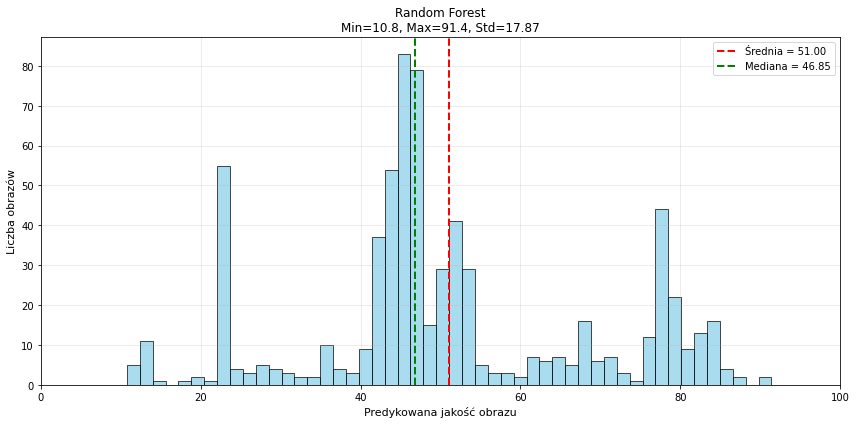


Statystyki predykcji jakości dla obrazów JFIF (Random Forest):
  Średnia: 51.00
  Mediana: 46.85
  Odch. std.: 17.87
  Min: 10.76
  Max: 91.41
  Q1 (25%): 43.23
  Q3 (75%): 63.66



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt




FILENAME = "results_RGB-faces-128x128.csv"

FILENAME = "results_VGG.csv"
FILENAME = "results_the_tufts.csv"
FILENAME = "results_ECVP_600.csv"

# Wczytanie danych JFIF
from_csv = pd.read_csv(FILENAME)
from_csv = from_csv.dropna()
X_from_csv = from_csv.drop(['filename', 'extension', 'estimated_quality'], axis=1)

print(f"Dane JFIF wczytane: {len(X_from_csv)} próbek")
print("=" * 70)

# Wybierz jeden model (np. Gradient Boosting)
model_name = 'Random Forest'
model = loaded_results[model_name]['model']

# Predykcja jakości dla obrazów JFIF
y_pred = model.predict(X_from_csv)
print(f"✓ Predykcja wykonana: {model_name}")

print("\n" + "=" * 70)

# Wizualizacja predykcji
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(y_pred, bins=50, alpha=0.7, edgecolor='black', color='skyblue')
ax.axvline(x=y_pred.mean(), color='r', linestyle='--', lw=2, 
          label=f'Średnia = {y_pred.mean():.2f}')
ax.axvline(x=np.median(y_pred), color='g', linestyle='--', lw=2, 
          label=f'Mediana = {np.median(y_pred):.2f}')
ax.set_xlabel('Predykowana jakość obrazu', fontsize=FONT_SIZE)
ax.set_ylabel('Liczba obrazów', fontsize=FONT_SIZE)
ax.set_title(f'{model_name}\nMin={y_pred.min():.1f}, Max={y_pred.max():.1f}, Std={y_pred.std():.2f}', 
            fontsize=FONT_SIZE)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=FONT_SIZE)
ax.set_xlim(0, 100)
ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

plt.tight_layout()
plt.savefig('jfif_quality_predictions_single_model.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nStatystyki predykcji jakości dla obrazów JFIF ({model_name}):")
print("="*70)
print(f"  Średnia: {y_pred.mean():.2f}")
print(f"  Mediana: {np.median(y_pred):.2f}")
print(f"  Odch. std.: {y_pred.std():.2f}")
print(f"  Min: {y_pred.min():.2f}")
print(f"  Max: {y_pred.max():.2f}")
print(f"  Q1 (25%): {np.percentile(y_pred, 25):.2f}")
print(f"  Q3 (75%): {np.percentile(y_pred, 75):.2f}")
print("\n" + "="*70)


# Predykcja jednostkowo - live

In [28]:
from index_script import detect_jpeg_compression
import os

def check_image(image_path):
    if not os.path.exists(image_path):
        print(f"Błąd: Plik '{image_path}' nie istnieje!")
        return
    
    print(f"Analiza pliku: {image_path}")
    
    result = detect_jpeg_compression(image_path)
    
    if result is None:
        print("Nie udało się obliczyć wskaźników")
        return
    
    # # Wyświetl wskaźniki
    # print("\nObliczone wskaźniki:")
    # for key, value in result.items():
    #     if key not in ['filename', 'extension']:
    #         if isinstance(value, float):
    #             print(f"{key:20s}: {value:.4f}")
    #         else:
    #             print(f"{key:20s}: {value}")
    
    #loaded_feature_columns = ['filename', 'extension', 'estimated_quality']
    loaded_feature_columns = ['blockiness_0', 'blockiness_1', 'blockiness_2', 'blockiness_3', 'blockiness_4', 'blockiness_5', 'blockiness_6', 'blockiness_7', 'blockiness_max', 'blockiness_mean', 'blockiness_std', 'energy_mean', 'energy_std', 'psnr']
    # Przygotuj dane do predykcji
    feature_dict = {col: result.get(col, 0) for col in loaded_feature_columns}
    X_single = pd.DataFrame([feature_dict])
    
    if X_single.isnull().any().any():
        print("\nBrakujące dane w wskaźnikach:")
        print(X_single.isnull().sum()[X_single.isnull().sum() > 0])
        return
    
    # Wybierz jeden model (np. Gradient Boosting)
    model_name = 'Random Forest'
    model = loaded_results[model_name]['model']

    # Predykcja jakości dla obrazów JFIF
    y_pred = model.predict(X_single)

    print(f"\nPredykowana jakość obrazu ({model_name}): {y_pred[0]:.2f}")
    print("-" * 80)


In [41]:
image_path = r"C:\Users\01sok\Downloads\test-224-224-1do1.png"


# check_image(r"C:\Users\01sok\Downloads\00001_930831_fa_a.ppm")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q95.jpg")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q80.jpg")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q80.png")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q60.jpg")
# check_image(r"C:\Users\01sok\Downloads\test-224-224-1do1.png")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q60q100.jpg")

# check_image(r"C:\Users\01sok\Downloads\test-500-700q80-1do1.png")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q80-1do1-doPNG-400-400.png")
# check_image(r"C:\Users\01sok\Downloads\test-500-700q80-1do1-doPNG-350-350.png")

check_image(r"C:\Users\01sok\Downloads\fakeface.jpg")
check_image(r"C:\Users\01sok\Downloads\fakeface-100x100.png")
check_image(r"C:\Users\01sok\Downloads\fakeface-500x500.png")
check_image(r"C:\Users\01sok\Downloads\fakeface-250x250.png")
check_image(r"C:\Users\01sok\Downloads\test-500-700q60q100-1000x1500.png")

Analiza pliku: C:\Users\01sok\Downloads\fakeface.jpg

Predykowana jakość obrazu (Random Forest): 64.25
--------------------------------------------------------------------------------
Analiza pliku: C:\Users\01sok\Downloads\fakeface-100x100.png

Predykowana jakość obrazu (Random Forest): 42.85
--------------------------------------------------------------------------------
Analiza pliku: C:\Users\01sok\Downloads\fakeface-500x500.png

Predykowana jakość obrazu (Random Forest): 93.03
--------------------------------------------------------------------------------
Analiza pliku: C:\Users\01sok\Downloads\fakeface-250x250.png

Predykowana jakość obrazu (Random Forest): 93.18
--------------------------------------------------------------------------------
Analiza pliku: C:\Users\01sok\Downloads\test-500-700q60q100-1000x1500.png

Predykowana jakość obrazu (Random Forest): 93.39
--------------------------------------------------------------------------------
